# Step 1. Turn DHS child records into one row per survey cluster.

Input : IPUMS-DHS extract (private)
Output: data/private/clusters.parquet  (private: contains GPS)

*Run on the author's computer. The DHS data are private, so the outputs shown here are summaries only (no cluster locations or survey records).*

In [1]:
import numpy as np
import pandas as pd
import pyreadstat
from config import DHS_FILE, PRIVATE, SSA, MIN_CHILDREN

In [2]:
cols = ["sample", "country", "year", "idhspsu", "intyear", "monthint", "urban",
        "wealthq", "educlvl", "kidalive", "kidagemo", "anemialvlkid",
        "opentoiletpsu", "gpslat", "gpslong", "perweight"]

In [3]:
print("Reading DHS extract (this takes a few minutes)...")
d, meta = pyreadstat.read_dta(str(DHS_FILE), usecols=cols)
print(f"  {len(d):,} child records, {d.country.nunique()} countries")

Reading DHS extract (this takes a few minutes)...


  3,015,819 child records, 63 countries


In [4]:
flow = [("All child records", len(d))]
def keep(mask, label):
    global d
    d = d[mask]
    flow.append((label, len(d)))

In [5]:
keep(d.country.isin(SSA.keys()), "Sub-Saharan Africa")
keep(d.kidalive == 1, "Child alive")
keep(d.kidagemo.between(6, 59), "Aged 6-59 months")
keep(d.anemialvlkid.isin([1, 2, 3, 4]), "Tested for anemia")
ok_gps = d.gpslat.notna() & d.gpslong.notna() & ~((d.gpslat == 0) & (d.gpslong == 0))
keep(ok_gps, "Cluster has GPS coordinates")
keep(d.opentoiletpsu.between(0, 100), "Cluster open defecation share available")
keep(d.urban.isin([1, 2]), "Urban/rural known")

In [6]:
d["anemic"] = (d.anemialvlkid <= 3).astype(float)            # any anemia (Hb < 11 g/dL, altitude-adjusted)
d["mod_sev"] = (d.anemialvlkid <= 2).astype(float)          # moderate or severe
d["mom_secondary"] = np.where(d.educlvl.isin([0, 1, 2, 3]), (d.educlvl >= 2).astype(float), np.nan)
d["country_name"] = d.country.map(SSA)
d["wealthq_ok"] = d.wealthq.where(d.wealthq.between(1, 5))

In [7]:
g = d.groupby("idhspsu")
cl = pd.DataFrame({
    "sample": g["sample"].first(),
    "country": g["country_name"].first(),
    "survey_year": g["year"].first(),
    "int_year": g["intyear"].agg(lambda s: s.mode().iat[0]).astype(int),
    "int_month": g["monthint"].agg(lambda s: s.mode().iat[0]).astype(int),
    "urban": (g["urban"].first() == 1).astype(int),
    "lat": g["gpslat"].first(),
    "lon": g["gpslong"].first(),
    "n_children": g.size(),
    "anemia_pct": g["anemic"].mean() * 100,
    "modsev_anemia_pct": g["mod_sev"].mean() * 100,
    "od_pct": g["opentoiletpsu"].first(),
    "wealth": g["wealthq_ok"].mean(),       # mean household wealth quintile, 1 = poorest, 5 = richest (relative to own country)
    "mom_secondary_pct": g["mom_secondary"].mean() * 100,
}).reset_index()

In [8]:
n_before = len(cl)
cl = cl[cl.n_children >= MIN_CHILDREN].copy()
flow.append((f"Children in clusters with >= {MIN_CHILDREN} tested children", int(cl.n_children.sum())))

In [9]:
cl.to_parquet(PRIVATE / "clusters.parquet", index=False)
pd.DataFrame(flow, columns=["step", "remaining"]).to_csv(PRIVATE / "sample_flow.csv", index=False)

In [10]:
print(pd.DataFrame(flow, columns=["step", "remaining"]).to_string(index=False))
print(f"Clusters: {n_before:,} -> {len(cl):,} kept; {cl.country.nunique()} countries; "
      f"{cl['sample'].nunique()} surveys; years {cl.int_year.min()}-{cl.int_year.max()}")
print(cl.groupby("country").size().sort_values(ascending=False).to_string())
print(cl[["anemia_pct", "od_pct", "wealth", "mom_secondary_pct", "n_children"]].describe().round(2).to_string())

                                          step  remaining
                             All child records    3015819
                            Sub-Saharan Africa    1475438
                                   Child alive    1363997
                              Aged 6-59 months     751676
                             Tested for anemia     319126
                   Cluster has GPS coordinates     284974
       Cluster open defecation share available     258530
                             Urban/rural known     258530
Children in clusters with >= 5 tested children     236822
Clusters: 29,943 -> 22,097 kept; 28 countries; 68 surveys; years 2000-2021
country
Rwanda          1805
Senegal         1742
Ethiopia        1366
Tanzania        1332
Mali            1285
Malawi          1162
Cameroon        1075
Nigeria         1055
Uganda          1054
Benin            983
Madagascar       982
Zimbabwe         982
Sierra Leone     946
Ghana            883
Burundi          852
Guinea           829
B

## Clusters per country

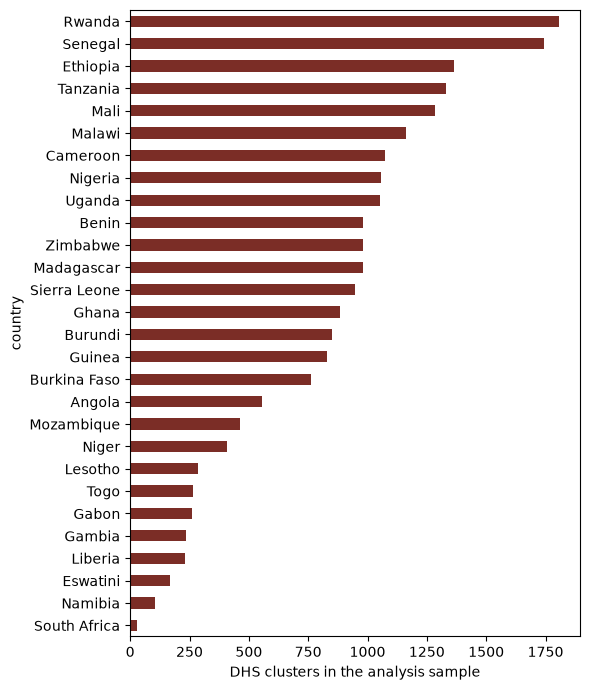

In [11]:
import matplotlib.pyplot as plt
ax = cl.country.value_counts().sort_values().plot.barh(figsize=(6, 7), color="#7b2d26")
ax.set_xlabel("DHS clusters in the analysis sample")
plt.tight_layout(); plt.show()

## How anemia and open defecation are distributed across clusters

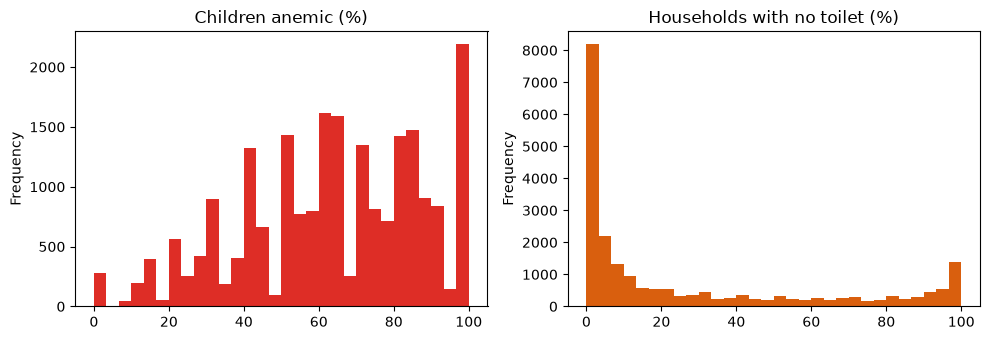

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
cl.anemia_pct.plot.hist(bins=30, ax=axes[0], color="#de2d26", title="Children anemic (%)")
cl.od_pct.plot.hist(bins=30, ax=axes[1], color="#d95f0e", title="Households with no toilet (%)")
plt.tight_layout(); plt.show()